## Explorative Data Analysis
- Read in Data from CDC-DWD for 2 German weather stations in order to determine latest frost dates

### Check data quality and consistency

In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv("data/data_OBS_DEU_P1D_T5CM_N.csv", 
                   index_col=False, parse_dates=[2] )
metadata = pd.read_csv("data/sdo_OBS_DEU_P1D_T5CM_N.csv")#, index_col='SDO_Name')

print(data.columns)
print(metadata.columns)
data.info()

Index(['Produkt_Code', 'SDO_ID', 'Zeitstempel', 'Wert', 'Qualitaet_Byte',
       'Qualitaet_Niveau'],
      dtype='str')
Index(['SDO_ID', 'SDO_Name', 'Geogr_Laenge', 'Geogr_Breite', 'Hoehe_ueber_NN',
       'Metadata_Link'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 81184 entries, 0 to 81183
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Produkt_Code      81184 non-null  str           
 1   SDO_ID            81184 non-null  int64         
 2   Zeitstempel       81184 non-null  datetime64[us]
 3   Wert              81184 non-null  float64       
 4   Qualitaet_Byte    81184 non-null  int64         
 5   Qualitaet_Niveau  81184 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 3.7 MB


In [24]:
print("number of missing values in all data: ", np.sum(data.isna()))
print("number of highest-quality data values of all data: ", round(100*np.sum(data['Qualitaet_Niveau']==10)/np.sum(data['Qualitaet_Niveau']>=0),1),"%")

number of missing values in all data:  0
number of highest-quality data values of all data:  52.2 %


### Data Quality
- DWD took care of data quality: no missing data and low-quality data is flagged as higher numbers in `Qualitaet_Niveau`, however we take it as is for now and assume it does not affect results of our analysis
  - data gap at Potsdam 1980-1990
- all data have at least quality niveau 5; 52% have the highest niveau (10) 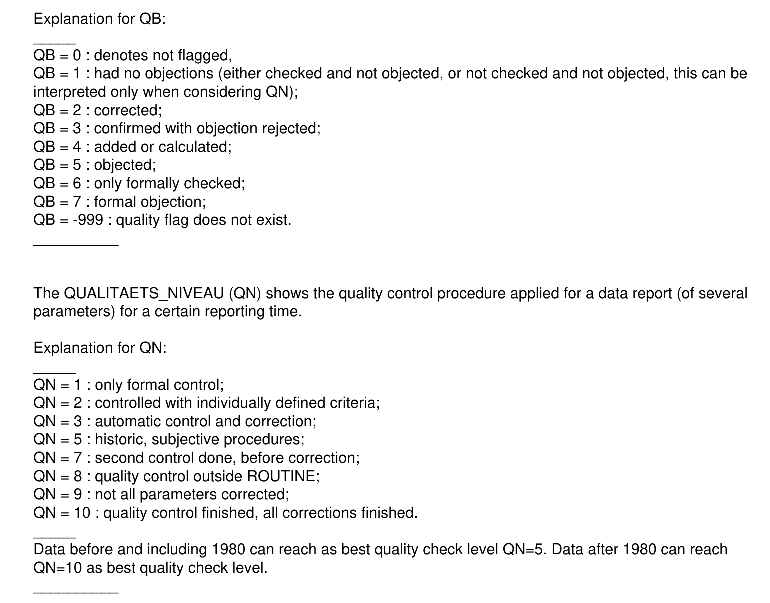

In [3]:
metadata.tail()

,SDO_ID,SDO_Name,Geogr_Laenge,Geogr_Breite,Hoehe_ueber_NN,Metadata_Link
0,1975,Hamburg-Fuhlsbüttel,"9,9881","53,6332",11.0,https://cdc.dwd.de/rest/metadata/station/html/...
1,2700,Kösching,"11,4872","48,8302",416.0,https://cdc.dwd.de/rest/metadata/station/html/...
2,3987,Potsdam,"13,0622","52,3812",81.0,https://cdc.dwd.de/rest/metadata/station/html/...


In [4]:
name_map = metadata.set_index('SDO_ID')['SDO_Name'].to_dict()
df_dict = {name_map[oid]: g for oid, g in data.groupby('SDO_ID')}
print(name_map)
df_dict['Kösching'].head()

In [49]:
#show gap
df_dict['Potsdam'].loc[68488:68489,['Zeitstempel','Wert']]

,Zeitstempel,Wert
68488,1980-12-31,5.2
68489,1991-01-01,-0.3


## Calculate last frost day before summer per year
Per definition, we assume that last frost day occurs before 1 July.

In [7]:
# Letzter Frosttag vor dem 1. Juli
last_frost_dict = {
    ort: g[(g['Wert'] < 0) & (g['Zeitstempel'].dt.month < 7)]
          .groupby(g['Zeitstempel'].dt.year)['Zeitstempel']
          .max()
    for ort, g in df_dict.items()
}

#last_frost_dict['Potsdam']

Zeitstempel
1946   1946-05-12
1947   1947-05-21
1948   1948-05-22
1949   1949-05-12
1950   1950-05-16
          ...    
2021   2021-05-08
2022   2022-04-23
2023   2023-05-03
2024   2024-04-25
2025   2025-05-08
Name: Zeitstempel, Length: 70, dtype: datetime64[us]

## First results: Visualizations
### Distribution of last frost day per station

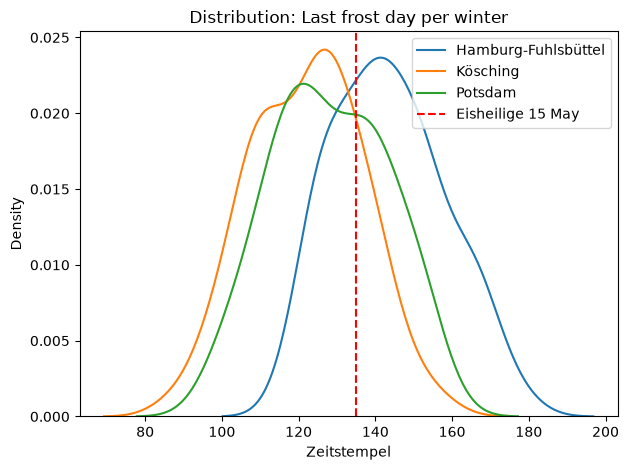

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

for i,station in enumerate(last_frost_dict):
    sns.kdeplot(last_frost_dict[station].dt.day_of_year, label=station)
    # print(station)

plt.axvline(135, color='red', linestyle='--', label=f'Eisheilige 15 May')
plt.title("Distribution: Last frost day per winter")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


### Results:
- Hamburg has more years with frosts after Eisheiligen, whereas Potsdam and Kösching do have less frosts after Eisheilige
> Is this mainly a dependence on latitude, or are there other factors? (PCA)
> Does elevation impact the timing of last frost?
- Strong interannual variability observed (n>30 years needed)
> Timing of cold-air outbreaks varies substantially

### Conclusion: 
- More data (stations) needed in order to identify the driving factors for timing of last frost
- ML-Prediction of last frost or day of year after which in x % of events no frost occurs

In [26]:
# print("Jahre in Hamburg mit letztem Frost bis Eisheiligen", sum(last_frost_1975.dt.day_of_year<=135))
# print("Jahre in Hamburg mit letztem Frost nach Eisheiligen", sum(last_frost_1975.dt.day_of_year>135))
# print("Jahre in Potsdam mit letztem Frost bis Eisheiligen", sum(last_frost_3987.dt.day_of_year<=135))
# print("Jahre in Potsdam mit letztem Frost nach Eisheiligen", sum(last_frost_3987.dt.day_of_year>135))

for i,station in enumerate(last_frost_dict):
    print(f"Station", station, np.median(last_frost_dict[station].dt.day_of_year)-135, 'days after Eisheilige')

Station Hamburg-Fuhlsbüttel 8.0 days after Eisheilige
Station Kösching -11.0 days after Eisheilige
Station Potsdam -8.5 days after Eisheilige


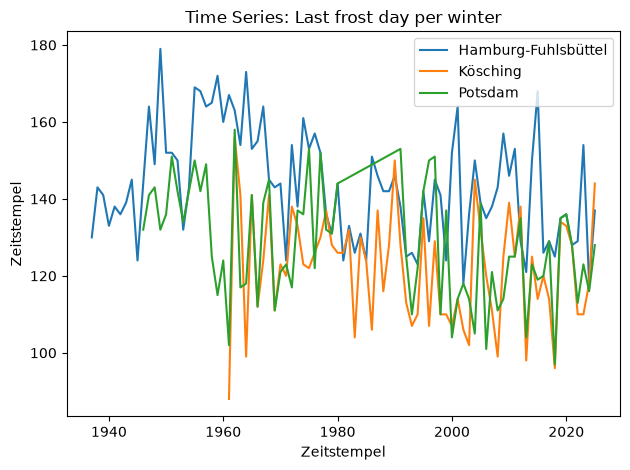

In [27]:
for i,station in enumerate(last_frost_dict):
    sns.lineplot(data=last_frost_dict[station].dt.day_of_year, label=station)

plt.legend(loc='upper right')
plt.title("Time Series: Last frost day per winter")
plt.tight_layout()
plt.show()

In [32]:
last_frost_dict['Potsdam'][30::].dt.day_of_year

Zeitstempel
1976    122
1977    152
1978    132
1979    131
1980    144
1991    153
1992    125
1993    110
1994    122
1995    142
1996    150
1997    151
1998    110
1999    137
2000    104
2001    114
2002    118
2003    114
2004    105
2005    139
2006    101
2007    121
2008    111
2009    114
2010    125
2011    125
2012    135
2013    104
2014    123
2015    119
2016    120
2017    129
2018     97
2019    135
2020    136
2021    128
2022    113
2023    123
2024    116
2025    128
Name: Zeitstempel, dtype: int32